In [1]:
import joblib
import os

preprocessor = joblib.load("preprocessing_pipeline.pkl")

print("Pipeline loaded successfully!")
print(preprocessor)

Pipeline loaded successfully!
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['occupancy', 'temperature', 'humidity',
                                  'co2_level', 'hvac_status', 'lighting_status',
                                  'outdoor_temperature']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['building_id', 'room_type'])])


In [2]:
print(os.listdir("feature_store"))

['building_features.csv', 'engineered_features.parquet', 'hourly_features.csv', 'retrieved_features.csv']


In [3]:
import pandas as pd
import numpy as np

# Load the retrieved features from Experiment 3
df = pd.read_csv("feature_store/retrieved_features.csv")

print("Feature store loaded successfully!")

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nTarget variable distribution:")
print(df["high_energy_usage"].value_counts())

Feature store loaded successfully!

Dataset shape: (2400, 22)

Column names:
['timestamp', 'building_id', 'room_type', 'occupancy', 'temperature', 'humidity', 'co2_level', 'hvac_status', 'lighting_status', 'outdoor_temperature', 'energy_kwh', 'high_energy_usage', 'hour', 'day_of_week', 'is_weekend', 'occupancy_per_co2', 'thermal_gap', 'hvac_occupancy_interaction', 'avg_occupancy', 'avg_energy', 'max_co2', 'hvac_usage_rate']

First five records:


,timestamp,building_id,room_type,occupancy,temperature,humidity,co2_level,hvac_status,lighting_status,outdoor_temperature,...,hour,day_of_week,is_weekend,occupancy_per_co2,thermal_gap,hvac_occupancy_interaction,avg_occupancy,avg_energy,max_co2,hvac_usage_rate
0,2025-01-01 00:00:00,B3,Lab,0,28.54,69.07,380.0,0,0,26.83,...,0,2,0,0.0,1.71,0,9.040486,3.796389,1307.1,0.657895
1,2025-01-01 01:00:00,B2,Library,0,30.94,79.02,380.0,0,0,28.85,...,1,2,0,0.0,2.09,0,9.523031,5.296357,1208.8,0.689450
2,2025-01-01 02:00:00,B4,Library,0,29.72,69.97,380.0,0,0,28.84,...,2,2,0,0.0,0.88,0,8.347439,5.697949,1214.3,0.679287
3,2025-01-01 03:00:00,B3,Office,0,29.89,67.74,393.2,1,0,26.93,...,3,2,0,0.0,2.96,0,9.040486,3.796389,1307.1,0.657895
4,2025-01-01 04:00:00,B1,Library,0,25.42,60.30,594.2,1,0,25.72,...,4,2,0,0.0,0.30,0,8.417092,4.386518,1196.3,0.681122



Target variable distribution:
high_energy_usage
0    1554
1     846
Name: count, dtype: int64


In [4]:
# Original features used in Experiment 2
original_features = [
    "occupancy",
    "temperature",
    "humidity",
    "co2_level",
    "hvac_status",
    "lighting_status",
    "outdoor_temperature",
    "building_id",
    "room_type"
]

# Separate target
y = df["high_energy_usage"].astype(int)

# Original input features
X_original = df[original_features].copy()

print("Original features:", X_original.shape)
print("Target:", y.shape)

Original features: (2400, 9)
Target: (2400,)


In [5]:
engineered_features = [
    "hour",
    "day_of_week",
    "is_weekend",
    "occupancy_per_co2",
    "thermal_gap",
    "hvac_occupancy_interaction",
    "avg_occupancy",
    "max_co2",
    "hvac_usage_rate"
]

X_engineered = df[engineered_features].copy()

print("Engineered features:", X_engineered.shape)

display(X_engineered.head())

Engineered features: (2400, 9)


,hour,day_of_week,is_weekend,occupancy_per_co2,thermal_gap,hvac_occupancy_interaction,avg_occupancy,max_co2,hvac_usage_rate
0,0,2,0,0.0,1.71,0,9.040486,1307.1,0.657895
1,1,2,0,0.0,2.09,0,9.523031,1208.8,0.689450
2,2,2,0,0.0,0.88,0,8.347439,1214.3,0.679287
3,3,2,0,0.0,2.96,0,9.040486,1307.1,0.657895
4,4,2,0,0.0,0.30,0,8.417092,1196.3,0.681122


In [6]:
from sklearn.model_selection import train_test_split

X_train_original, X_test_original, \
X_train_eng, X_test_eng, \
y_train, y_test = train_test_split(
    X_original,
    X_engineered,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train_original))
print("Testing records:", len(X_test_original))

Training records: 1920
Testing records: 480


In [7]:
X_train_processed = preprocessor.transform(
    X_train_original
)

X_test_processed = preprocessor.transform(
    X_test_original
)

print("Training after preprocessing:",
      X_train_processed.shape)

print("Testing after preprocessing:",
      X_test_processed.shape)

Training after preprocessing: (1920, 15)
Testing after preprocessing: (480, 15)


In [8]:
from sklearn.impute import SimpleImputer

eng_imputer = SimpleImputer(strategy="median")

X_train_eng_processed = eng_imputer.fit_transform(
    X_train_eng
)

X_test_eng_processed = eng_imputer.transform(
    X_test_eng
)

print("Engineered training features:",
      X_train_eng_processed.shape)

print("Engineered testing features:",
      X_test_eng_processed.shape)

Engineered training features: (1920, 9)
Engineered testing features: (480, 9)


In [9]:
from scipy.sparse import hstack, csr_matrix

X_train_final = hstack([
    csr_matrix(X_train_processed),
    csr_matrix(X_train_eng_processed)
]).tocsr()

X_test_final = hstack([
    csr_matrix(X_test_processed),
    csr_matrix(X_test_eng_processed)
]).tocsr()

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (1920, 24)
Final testing shape: (480, 24)


In [18]:
import importlib.util

print("MLflow installed:",
      importlib.util.find_spec("mlflow") is not None)

MLflow installed: True


In [19]:
import mlflow
import mlflow.sklearn

print("MLflow version:", mlflow.__version__)

mlflow.set_tracking_uri("sqlite:///mlflow.db")

mlflow.set_experiment(
    "Smart_Campus_Energy_Prediction"
)

print("MLflow experiment created successfully!")

MLflow version: 3.15.1


2026/11/01 23:03:04 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/01 23:03:04 INFO mlflow.store.db.utils: Updating database tables
2026/11/01 23:03:06 INFO mlflow.tracking.fluent: Experiment with name 'Smart_Campus_Energy_Prediction' does not exist. Creating a new experiment.


MLflow experiment created successfully!


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Six machine learning models initialized!")

Six machine learning models initialized!


In [29]:
runs = mlflow.search_runs()

display(
    runs[[
        "tags.mlflow.runName",
        "metrics.accuracy",
        "metrics.f1_score"
    ]]
)

,tags.mlflow.runName,metrics.accuracy,metrics.f1_score
0,Gradient Boosting,0.879167,0.824242
1,KNN,0.847917,0.773994
2,SVM,0.647917,0.000000
3,Random Forest,0.900000,0.854545
4,Decision Tree,0.854167,0.789157
5,Random Forest,0.900000,0.854545
6,Decision Tree,0.854167,0.789157
7,Logistic Regression,0.900000,0.857988
8,Decision Tree,0.854167,0.789157
9,Logistic Regression,0.900000,0.857988


,tags.mlflow.runName,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc,status
0,Gradient Boosting,0.879167,0.844720,0.804734,0.824242,0.959056,FINISHED
1,KNN,0.847917,0.811688,0.739645,0.773994,0.905392,FINISHED
2,SVM,0.647917,0.000000,0.000000,0.000000,0.847200,FINISHED
3,Random Forest,0.900000,0.875776,0.834320,0.854545,0.953310,FINISHED
4,Decision Tree,0.854167,0.803681,0.775148,0.789157,0.836127,FINISHED
7,Logistic Regression,0.900000,0.857988,0.857988,0.857988,0.965144,FINISHED
9,Logistic Regression,0.900000,0.857988,0.857988,0.857988,0.965144,FINISHED


Successfully completed models: 7


In [30]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.9,0.857988,0.857988,0.857988,0.965144


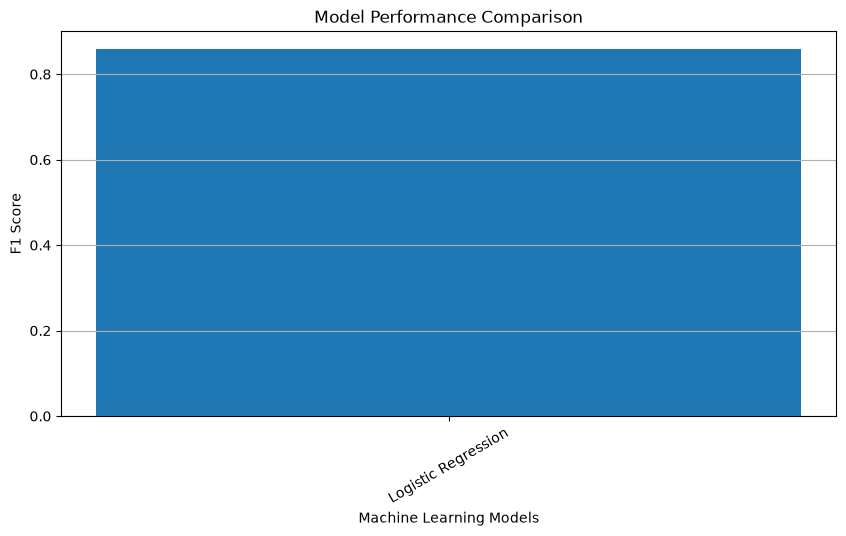

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["F1 Score"]
)

plt.xlabel("Machine Learning Models")
plt.ylabel("F1 Score")
plt.title("Model Performance Comparison")

plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

In [32]:
best_model_name = results_df.iloc[0]["Model"]

best_model = models[best_model_name]

best_f1 = results_df.iloc[0]["F1 Score"]

print("Best Model:", best_model_name)
print("Best F1 Score:", best_f1)

Best Model: Logistic Regression
Best F1 Score: 0.8579881656804734


In [34]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.base import clone
import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn

# Convert sparse matrices to dense arrays if required
X_train_tune = X_train_final.toarray() if hasattr(X_train_final, "toarray") else X_train_final
X_test_tune = X_test_final.toarray() if hasattr(X_test_final, "toarray") else X_test_final

# Cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Hyperparameter combinations
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 1, 10],
        "class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "max_depth": [None, 5, 10, 20],
        "min_samples_split": [2, 5, 10]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5]
    },
    "SVM": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"],
        "class_weight": [None, "balanced"]
    },
    "KNN": {
        "n_neighbors": [3, 5, 7, 9],
        "weights": ["uniform", "distance"]
    },
    "Gradient Boosting": {
        "n_estimators": [100, 150],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3]
    }
}

print("Data ready for hyperparameter tuning!")
print("Training shape:", X_train_tune.shape)
print("Testing shape:", X_test_tune.shape)

Data ready for hyperparameter tuning!
Training shape: (1920, 24)
Testing shape: (480, 24)


In [47]:
tuned_models = {}
tuning_results = []

for model_name, base_model in models.items():

    print("\nTuning:", model_name)

    grid = GridSearchCV(
        estimator=clone(base_model),
        param_grid=param_grids[model_name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(X_train_tune, y_train)

    best_model = grid.best_estimator_
    tuned_models[model_name] = best_model

    # Evaluate on test data
    y_pred = best_model.predict(X_test_tune)

    if hasattr(best_model, "predict_proba"):
        y_prob = best_model.predict_proba(X_test_tune)[:, 1]
    else:
        y_prob = best_model.decision_function(X_test_tune)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    tuning_results.append({
        "Model": model_name,
        "Best CV F1": grid.best_score_,
        "Test Accuracy": accuracy,
        "Test Precision": precision,
        "Test Recall": recall,
        "Test F1": f1,
        "Test ROC-AUC": roc_auc,
        "Best Parameters": grid.best_params_
    })

    # Log tuning results in MLflow
    with mlflow.start_run(run_name="Tuned_" + model_name):
        mlflow.log_params(grid.best_params_)
        mlflow.log_param("model_name", model_name)
        mlflow.log_metric("best_cv_f1", grid.best_score_)
        mlflow.log_metric("test_accuracy", accuracy)
        mlflow.log_metric("test_precision", precision)
        mlflow.log_metric("test_recall", recall)
        mlflow.log_metric("test_f1", f1)
        mlflow.log_metric("test_roc_auc", roc_auc)

        mlflow.sklearn.log_model(
            sk_model=best_model,
            name="model",
            serialization_format="cloudpickle"
        )

    print("Best parameters:", grid.best_params_)
    print("Test F1 score:", round(f1, 4))

print("\nHyperparameter tuning completed!")

import warnings
warnings.filterwarnings('ignore')


Tuning: Logistic Regression


2026/11/01 23:25:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Best parameters: {'C': 10, 'class_weight': 'balanced'}
Test F1 score: 0.85

Tuning: Decision Tree


2026/11/01 23:26:02 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Best parameters: {'max_depth': 10, 'min_samples_split': 10}
Test F1 score: 0.7751

Tuning: Random Forest


2026/11/01 23:26:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (3 outputs left out)

2026/11/01 23:26:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Best parameters: {'n_neighbors': 7, 'weights': 'uniform'}
Test F1 score: 0.7926

Tuning: Gradient Boosting


2026/11/01 23:26:47 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 150}
Test F1 score: 0.8263

Hyperparameter tuning completed!


In [48]:
tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    by="Test F1",
    ascending=False
).reset_index(drop=True)

display(tuning_results_df)

,Model,Best CV F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Best Parameters
0,SVM,0.834419,0.904167,0.859649,0.869822,0.864706,0.962823,"{'C': 1, 'class_weight': None, 'kernel': 'line..."
1,Logistic Regression,0.834708,0.887500,0.801047,0.905325,0.850000,0.966038,"{'C': 10, 'class_weight': 'balanced'}"
2,Random Forest,0.806560,0.887500,0.844311,0.834320,0.839286,0.953043,"{'max_depth': None, 'min_samples_split': 5, 'n..."
3,Gradient Boosting,0.818610,0.879167,0.836364,0.816568,0.826347,0.957229,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."
4,KNN,0.757488,0.860417,0.831169,0.757396,0.792570,0.918473,"{'n_neighbors': 7, 'weights': 'uniform'}"
5,Decision Tree,0.771014,0.841667,0.775148,0.775148,0.775148,0.880211,"{'max_depth': 10, 'min_samples_split': 10}"


In [37]:
best_row = tuning_results_df.loc[
    tuning_results_df["Best CV F1"].idxmax()
]

best_model_name = best_row["Model"]
best_model = tuned_models[best_model_name]

print("Final Selected Model:", best_model_name)
print("Best Cross-Validation F1:", best_row["Best CV F1"])
print("Test F1 Score:", best_row["Test F1"])
print("Test Accuracy:", best_row["Test Accuracy"])
print("Test ROC-AUC:", best_row["Test ROC-AUC"])
print("Best Parameters:", best_row["Best Parameters"])

Final Selected Model: Logistic Regression
Best Cross-Validation F1: 0.8347084335549285
Test F1 Score: 0.85
Test Accuracy: 0.8875
Test ROC-AUC: 0.9660381666317852
Best Parameters: {'C': 10, 'class_weight': 'balanced'}


In [38]:
registered_model_name = "SmartCampusEnergyBestModel"

with mlflow.start_run(run_name="Final_Best_Model"):

    mlflow.log_param("selected_model", best_model_name)
    mlflow.log_param("selection_metric", "5-fold CV F1")

    mlflow.log_metrics({
        "test_accuracy": float(best_row["Test Accuracy"]),
        "test_precision": float(best_row["Test Precision"]),
        "test_recall": float(best_row["Test Recall"]),
        "test_f1": float(best_row["Test F1"]),
        "test_roc_auc": float(best_row["Test ROC-AUC"])
    })

    model_info = mlflow.sklearn.log_model(
        sk_model=best_model,
        name="final_model",
        serialization_format="cloudpickle"
    )

    best_model_uri = model_info.model_uri

# Register the logged model
registered_model = mlflow.register_model(
    model_uri=best_model_uri,
    name=registered_model_name
)

print("Model registered successfully!")
print("Model Name:", registered_model.name)
print("Model Version:", registered_model.version)

2026/11/01 23:21:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Model registered successfully!
Model Name: SmartCampusEnergyBestModel
Model Version: 1


Successfully registered model 'SmartCampusEnergyBestModel'.
Created version '1' of model 'SmartCampusEnergyBestModel'.


In [39]:
model_uri = f"models:/{registered_model_name}/{registered_model.version}"

loaded_model = mlflow.sklearn.load_model(model_uri)

print("Registered model loaded successfully!")

Registered model loaded successfully!


In [40]:
sample_data = X_test_tune[:5]

predictions = loaded_model.predict(sample_data)

print("Sample Predictions:", predictions)
print("Actual Values:", y_test.iloc[:5].values)

Sample Predictions: [1 0 0 0 1]
Actual Values: [1 0 1 0 1]


In [41]:
prediction_results = pd.DataFrame({
    "Actual Value": y_test.iloc[:5].values,
    "Predicted Value": predictions
})

display(prediction_results)

,Actual Value,Predicted Value
0,1,1
1,0,0
2,1,0
3,0,0
4,1,1


In [42]:
print("MLflow Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", mlflow.get_experiment_by_name(
    "Smart_Campus_Energy_Prediction"
).name)

MLflow Tracking URI: sqlite:///mlflow.db
Experiment: Smart_Campus_Energy_Prediction


In [46]:
import joblib

joblib.dump(best_model, "best_smart_campus_model.pkl")
joblib.dump(eng_imputer, "engineered_features_imputer.pkl")

tuning_results_df.to_csv(
    "model_tuning_results.csv",
    index=False
)

print("Experiment 4 outputs saved successfully!")

Experiment 4 outputs saved successfully!


In [49]:
import os
import mlflow
from mlflow import MlflowClient

print("Current folder:", os.getcwd())
print("Tracking URI:", mlflow.get_tracking_uri())
print("Database exists:", os.path.exists("mlflow.db"))

client = MlflowClient()

print("\nExperiments:")
for exp in client.search_experiments():
    print(exp.name, exp.experiment_id)

print("\nRegistered Models:")
for model in client.search_registered_models():
    print(model.name)

Current folder: C:\Users\eswar\MLOPS
Tracking URI: sqlite:///mlflow.db
Database exists: True

Experiments:
Smart_Campus_Energy_Prediction 1
Default 0

Registered Models:
SmartCampusEnergyBestModel
